# 01 · End-member mixing analysis, EMMA (Figure 11, SM10, SM11, SM12)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development (under review).

**What this notebook does**

Quantifies the contributions of three recharge end-members to groundwater with a three-end-member mass balance on two conservative tracers, δ¹⁸O and Cl⁻ (Liu and Yamanaka, 2012; Bouimouass et al., 2024):
1. Merges the isotope dataset with Na⁺, Cl⁻ and the SOM cluster of each sample.
2. **Screens the conservative behaviour of Cl⁻** with the Na⁺/Cl⁻ molar ratio (Figure SM10): samples with Cl⁻ > 100 mg/L and Na/Cl < 0.7 are flagged reactive and excluded.
3. Keeps the **148 groundwater samples** with both tracers and conservative Cl⁻.
4. Defines the end-members from the extremes of the data: EM1 mountain-front recharge (MFR), EM2 regional mountain-block recharge (MBR), EM3 front-slope MBR.
5. Draws the mixing diagrams (Figure 11), solves the mass balance for each sample (**132 valid**), propagates the end-member uncertainty by Monte Carlo (N = 1,000), and summarizes the mixing proportions (Figures SM11, SM12).

| | |
|---|---|
| **Inputs** | `outputs/intermediate/data_EMMA1.xlsx`, `data/All_data1.xlsx`, `outputs/intermediate/data_final_with_clusters.xlsx` |
| **Figures** | `Figure11_d18O_d2H_vs_Cl_mixing_panel`, `SM10_NaCl_screening`, `SM11_EMMA_stacked_bar`, `SM12_EMMA_boxplots` |
| **Tables** | `outputs/tables/EMMA_results.xlsx` (valid and invalid samples, end-members, summary) |
| **Next notebook** | `02_EMMA_sensitivity.ipynb` |

*Note: the tritium cross-check of the mixing results (Figure SM13) needs the ³H column, which is not part of the shared data file (available on request); that section is skipped automatically when the column is absent.*

### <font color='orange'> **1) Packages, settings and paths** </font>

In [14]:
# ── imports ──────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon
from matplotlib.path import Path
import seaborn as sns
import pathlib
import warnings

warnings.filterwarnings('ignore')

# ── global plot settings ───────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 800,
    'font.family': 'serif',
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.25,
    'grid.color': 'gray',
})
DPI = 800
# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

### <font color='orange'> **2) Load the data** </font>

In [15]:
# ── input files ──────────────────────────────────────────────────────
FILE_EMMA1 = DIR_INTERMED / "data_EMMA1.xlsx"                 # from 04_isotopes/01_isotope_dataset.ipynb
FILE_RAW   = ROOT / "data" / "All_data1.xlsx"
FILE_SOM1  = DIR_INTERMED / "data_final_with_clusters.xlsx"   # from 03_PCA_SOM_HCA/02_HCA_clustering.ipynb

for tag, fp in [("Isotopes", FILE_EMMA1), ("Raw data", FILE_RAW), ("Clusters", FILE_SOM1)]:
    assert fp.exists(), f"MISSING: {fp}"
    print(f"  {tag:9s} -> {fp.relative_to(ROOT)}")

df_emma1 = pd.read_excel(FILE_EMMA1)
df_raw   = pd.read_excel(FILE_RAW)
df_som1  = pd.read_excel(FILE_SOM1)

print(f"\ndf_emma1 : {df_emma1.shape}")
print(f"df_raw   : {df_raw.shape}")
print(f"df_som1  : {df_som1.shape}")

  Isotopes  -> outputs\intermediate\data_EMMA1.xlsx
  Raw data  -> data\All_data1.xlsx
  Clusters  -> outputs\intermediate\data_final_with_clusters.xlsx

df_emma1 : (345, 10)
df_raw   : (540, 29)
df_som1  : (406, 38)


### <font color='orange'> **3) Merge the datasets** </font>

In [16]:
# ── merge Na+, Cl-, EC from raw data ────────────────────────────────────────
cols_raw = ['SampleID', 'Na (mg/L)', 'Cl (mg/L)', 'EC (μS/cm)']
df_raw_sub = df_raw[cols_raw].drop_duplicates(subset='SampleID')

df = df_emma1.merge(df_raw_sub, on='SampleID', how='left')
print(f'After raw merge : {df.shape[0]} rows, '
      f'Cl non-null = {df["Cl (mg/L)"].notna().sum()}')

# ── merge the SOM cluster ───────────────────────────────────────────────
cols_som = ['SampleID', 'Cluster']
df_som_sub = df_som1[cols_som].drop_duplicates(subset='SampleID')

df = df.merge(df_som_sub, on='SampleID', how='left')
print(f'After SOM merge : Cluster non-null = {df["Cluster"].notna().sum()}')

# ── tritium (only if the 3H column is present in the data file) ─────────
def parse_3h(val):
    """Convert mixed-format 3H values to float."""
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).strip()
    if s.lower() in ('below detection', 'bd', 'nd', ''):
        return 0.0
    # handle strings like '4,1 ±0,5'
    s = s.replace(',', '.')
    if '±' in s:
        s = s.split('±')[0].strip()
    try:
        return float(s)
    except ValueError:
        return np.nan

HAS_3H = '3H' in df.columns
if HAS_3H:
    df['3H_value'] = df['3H'].apply(parse_3h)
    print(f'3H parsed: {df["3H_value"].notna().sum()} non-null values')
else:
    print('3H column not in the data file: the tritium cross-check (section 12) will be skipped.')
print(f'\nFinal merged DataFrame: {df.shape}')
df.head(3)

After raw merge : 345 rows, Cl non-null = 263
After SOM merge : Cluster non-null = 211
3H column not in the data file: the tritium cross-check (section 12) will be skipped.

Final merged DataFrame: (345, 14)


,Reference,SampleID,X,Y,Z,Sampling date,Type,δ18O (‰ VSMOW),δ2H (‰ VSMOW),d-excess (‰),Na (mg/L),Cl (mg/L),EC (μS/cm),Cluster
0,"(EL FARCHOUNI et al., 2025)",S1,264704.0,468828.0,2809.70,2025-01-10 00:00:00,Snow,-9.91,-63.4,15.88,NaN,NaN,NaN,NaN
1,"(EL FARCHOUNI et al., 2025)",S2,264894.0,469092.0,2728.25,2025-01-10 00:00:00,Snow,-11.44,-72.8,18.72,NaN,NaN,NaN,NaN
2,"(EL FARCHOUNI et al., 2025)",S3,264933.0,469332.0,2703.40,2025-01-10 00:00:00,Snow,-10.13,-63.0,18.04,NaN,NaN,NaN,NaN


### <font color='orange'> **4) Na⁺/Cl⁻ conservative screening (Figure SM10)** </font>

Cl⁻ is used as a conservative tracer in EMMA. To verify its conservative behaviour,  
we compute the Na+/Cl⁻ molar ratio. Samples are flagged as **reactive** (non-conservative Cl⁻)  
only if **both** conditions are met:  
1. Cl⁻ > 100 mg/L (concentrated enough for anthropogenic or dissolution influence)  
2. Na/Cl molar ratio < 0.7 (excess Cl⁻ relative to halite dissolution line)

Total with Na & Cl : 214
Conservative Cl-   : 202
Reactive (flagged) : 12


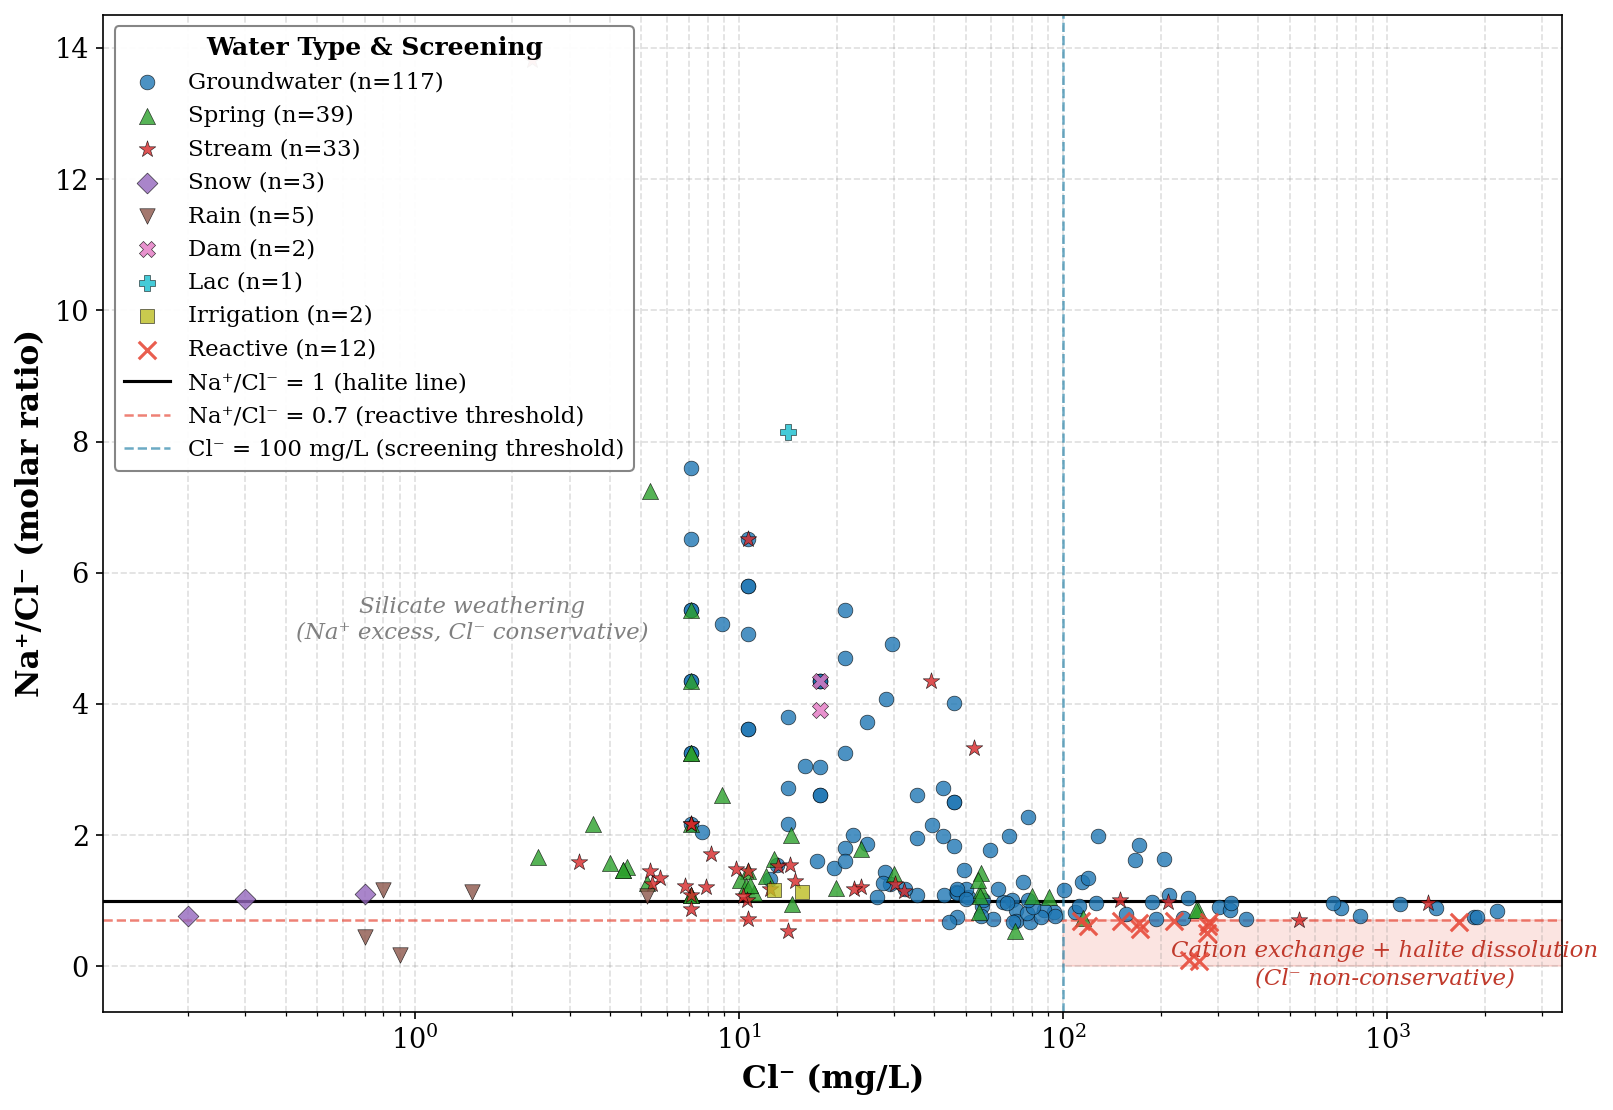

Saved: SM10_NaCl_screening
✓ Matches the article: 214 samples with Na and Cl, 202 conservative (94.4 %), 12 reactive.


In [17]:
# ── molar masses ──────────────────────────────────────────────────────────────
M_Na = 22.99
M_Cl = 35.45

mask_chem = df["Na (mg/L)"].notna() & df["Cl (mg/L)"].notna()
df_chem = df.loc[mask_chem].copy()

df_chem["Na_meq"] = df_chem["Na (mg/L)"] / M_Na
df_chem["Cl_meq"] = df_chem["Cl (mg/L)"] / M_Cl
df_chem["NaCl_ratio"] = df_chem["Na_meq"] / df_chem["Cl_meq"]

# ── two-condition flag ──────────────────────────────────────────────
df_chem["reactive"] = (df_chem["Cl (mg/L)"] > 100) & (df_chem["NaCl_ratio"] < 0.7)

n_total = len(df_chem)
n_reactive = df_chem["reactive"].sum()
n_conservative = n_total - n_reactive
print(f"Total with Na & Cl : {n_total}")
print(f"Conservative Cl-   : {n_conservative}")
print(f"Reactive (flagged) : {n_reactive}")

# ── propagate flag back to main df ────────────────────────────────────────
df["NaCl_ratio"] = np.nan
df.loc[mask_chem, "NaCl_ratio"] = df_chem["NaCl_ratio"].values
df["reactive_Cl"] = False
df.loc[mask_chem, "reactive_Cl"] = df_chem["reactive"].values

# ── Font sizes ───────────────────────────────────────────────────────────
LABEL_FS      = 15
TICK_FS       = 13
LEG_FS        = 11
LEG_TITLE_FS  = 12
ANNO_FS       = 11

# ── Type styles ─────────────────────────────────────────────────────────────
TYPE_STYLE = {
    "Groundwater":     {"marker": "o", "color": "#1f77b4", "size": 35},
    "Spring":          {"marker": "^", "color": "#2ca02c", "size": 45},
    "Stream":          {"marker": "*", "color": "#d62728", "size": 55},
    "Snow":            {"marker": "D", "color": "#9467bd", "size": 35},
    "Rain":            {"marker": "v", "color": "#8c564b", "size": 40},
    "Dam":             {"marker": "X", "color": "#e377c2", "size": 45},
    "Lac":             {"marker": "P", "color": "#17becf", "size": 45},
    "Irrigation":      {"marker": "s", "color": "#bcbd22", "size": 35},
    "Canal (Zaraba)":  {"marker": "h", "color": "#ff7f0e", "size": 45},
}

# ── plot ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 7.5))

ax.set_xscale("log")

# ── Conservative samples by Type ─────────────────────────────────────────
df_cons = df_chem[~df_chem["reactive"]]
df_reac = df_chem[df_chem["reactive"]]

for wtype, style in TYPE_STYLE.items():
    subset = df_cons[df_cons["Type"] == wtype]
    if len(subset) == 0:
        continue
    ax.scatter(subset["Cl (mg/L)"], subset["NaCl_ratio"],
               marker=style["marker"], c=style["color"], s=style["size"] + 15,
               edgecolors="black", linewidths=0.3, alpha=0.8,
               label=f"{wtype} (n={len(subset)})", zorder=3)

# ── Reactive samples (red X) ────────────────────────────────────────────
ax.scatter(df_reac["Cl (mg/L)"], df_reac["NaCl_ratio"],
           c="#E74C3C", s=70, marker="x", linewidths=1.5, alpha=0.9,
           zorder=4, label=f"Reactive (n={len(df_reac)})")

# ── Reference lines ───────────────────────────────────────────────────────
ax.axhline(1.0, color="k", ls="-", lw=1.5, zorder=2, label="Na⁺/Cl⁻ = 1 (halite line)")
ax.axhline(0.7, color="#E74C3C", ls="--", lw=1.2, alpha=0.7, zorder=2, label="Na⁺/Cl⁻ = 0.7 (reactive threshold)")
ax.axvline(100, color="#2E86AB", ls="--", lw=1.2, alpha=0.7, zorder=2, label="Cl⁻ = 100 mg/L (screening threshold)")

# ── Annotations ─────────────────────────────────────────────────────────
txt1 = "Silicate weathering\n(Na⁺ excess, Cl⁻ conservative)"
ax.annotate(txt1, xy=(1.5, 5), fontsize=ANNO_FS, fontstyle="italic", color="gray", ha="center")

# ── Annotation position (adjust these values to move the label) ──────
LABEL2_X = 980   # x position (Cl- in mg/L, log scale)
LABEL2_Y = 0.07   # y position (Na/Cl ratio)
txt2a = "Cation exchange + halite dissolution"
txt2b = "(Cl⁻ non-conservative)"
ax.text(LABEL2_X, LABEL2_Y, txt2a, fontsize=ANNO_FS, fontstyle="italic",
        color="#C0392B", ha="center", va="bottom")
ax.text(LABEL2_X, LABEL2_Y - 0.08, txt2b, fontsize=ANNO_FS, fontstyle="italic",
        color="#C0392B", ha="center", va="top")

# ── Axes ───────────────────────────────────────────────────────────────────
ax.set_xscale("log")
ax.set_xlabel("Cl⁻ (mg/L)", fontsize=LABEL_FS, fontweight="bold")
ax.set_ylabel("Na⁺/Cl⁻ (molar ratio)", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(labelsize=TICK_FS)
ax.grid(True, ls="--", alpha=0.25, color="gray", which="both")

# ── Legend ──────────────────────────────────────────────────────────────
handles, labels = ax.get_legend_handles_labels()
leg = ax.legend(handles, labels, loc="upper left", fontsize=LEG_FS,
                framealpha=0.95, edgecolor="gray",
                title="Water Type & Screening",
                title_fontproperties={"weight": "bold", "size": LEG_TITLE_FS})

# ── Shaded reactive zone: fill to right edge ─────────────────────────
x_right = ax.get_xlim()[1]
x_fill = np.logspace(2, np.log10(x_right * 10), 500)
ax.fill_between(x_fill, 0, 0.7, alpha=0.15, color="#E74C3C", zorder=0,
                label="Reactive zone (Cl⁻ non-conservative)")
ax.set_xlim(right=x_right)  # restore original xlim so fill doesn't extend axis

fig.tight_layout()
fig.savefig(DIR_FIGURES / "SM10_NaCl_screening.png", dpi=800, bbox_inches="tight")
plt.show()
print("Saved: SM10_NaCl_screening")

# ── Check against the article ────────────────────────────────────────
assert (n_total, n_conservative, n_reactive) == (214, 202, 12)
print("✓ Matches the article: 214 samples with Na and Cl, 202 conservative (94.4 %), 12 reactive.")

### <font color='orange'> **5) Define EMMA-ready dataset (groundwater only)** </font>

Following Bouimouass et al. (2024), EMMA is applied **only** to groundwater samples  
(the mixed waters). Surface water, rain, snow, and extreme wells are used to  
**define** end-members but are NOT targets of the mixing calculation.

In [18]:
# ── filter: groundwater + both tracers + conservative Cl- ──────────────────
mask_gw = df['Type'] == 'Groundwater'
mask_d18O = df['δ18O (‰ VSMOW)'].notna()
mask_cl = df['Cl (mg/L)'].notna()
mask_conservative = ~df['reactive_Cl']

df_emma = df.loc[mask_gw & mask_d18O & mask_cl & mask_conservative].copy()
df_emma = df_emma.reset_index(drop=True)

d18O_col = 'δ18O (‰ VSMOW)'
d2H_col = 'δ2H (‰ VSMOW)'
cl_col = 'Cl (mg/L)'

d18O_min = df_emma[d18O_col].min()
d18O_max = df_emma[d18O_col].max()
cl_min = df_emma[cl_col].min()
cl_max = df_emma[cl_col].max()

print(f'Groundwater with d18O & Cl- (conservative): {len(df_emma)} samples')
print(f'd18O range: {d18O_min:.2f} to {d18O_max:.2f}')
print(f'Cl- range : {cl_min:.1f} to {cl_max:.1f} mg/L')

# ── export ───────────────────────────────────────────────────────────────────
df_emma.to_excel(DIR_INTERMED / 'EMMA_ready_conservative.xlsx', index=False)
print('Exported EMMA-ready dataset.')

Groundwater with d18O & Cl- (conservative): 148 samples
d18O range: -9.37 to -3.97
Cl- range : 7.1 to 2176.1 mg/L
Exported EMMA-ready dataset.


### <font color='orange'> **6) Define end-members from our data** </font>

End-members are defined from the **extremes** of our own data cloud, not copied from  
literature values. This follows the approach of Bouimouass et al. (2024):

| End-member | Represents | Selection rule |
|:-----------|:-----------|:---------------|
| **EM1 (MFR)** | Mountain-Front Recharge | Mean of the 5 most depleted δ¹⁸O stream/spring samples |
| **EM2 (Regional MBR)** | Deep regional groundwater | Mean of the 3 highest-Cl⁻ groundwater samples |
| **EM3 (Front-slope MBR)** | Shallow foothill recharge | Mean of the 5 most enriched δ¹⁸O samples with Cl⁻ < 100 mg/L |

**Key principle:** EM-defining samples (streams for EM1, extreme GW for EM2, enriched low-Cl samples for EM3) are used to define the triangle vertices but are NOT included as EMMA mixing targets.

In [19]:
# ── build working pool (samples with both δ18O and Cl-) ────────────────────
pool = df.loc[df['δ18O (‰ VSMOW)'].notna() & df['Cl (mg/L)'].notna()].copy()

# ── EM1 (MFR): 5 most depleted δ18O from streams/springs ─────────────────
em1_pool = pool[pool['Type'].isin(['Stream', 'Spring'])]
em1_samples = em1_pool.nsmallest(5, 'δ18O (‰ VSMOW)')
EM1_d18O = em1_samples['δ18O (‰ VSMOW)'].mean()
EM1_Cl   = em1_samples['Cl (mg/L)'].mean()
EM1_d18O_sd = em1_samples['δ18O (‰ VSMOW)'].std()
EM1_Cl_sd   = em1_samples['Cl (mg/L)'].std()
print(f'EM1 (MFR)          : \u03b418O = {EM1_d18O:.2f} \u00b1 {EM1_d18O_sd:.2f}, '
      f'Cl = {EM1_Cl:.1f} \u00b1 {EM1_Cl_sd:.1f} mg/L  (n={len(em1_samples)})')

# ── EM2 (Regional MBR): 3 highest-Cl- groundwater ─────────────────────
em2_pool = pool[pool['Type'] == 'Groundwater']
em2_samples = em2_pool.nlargest(3, 'Cl (mg/L)')
EM2_d18O = em2_samples['δ18O (‰ VSMOW)'].mean()
EM2_Cl   = em2_samples['Cl (mg/L)'].mean()
EM2_d18O_sd = em2_samples['δ18O (‰ VSMOW)'].std()
EM2_Cl_sd   = em2_samples['Cl (mg/L)'].std()
print(f'EM2 (Regional MBR)     : \u03b418O = {EM2_d18O:.2f} \u00b1 {EM2_d18O_sd:.2f}, '
      f'Cl = {EM2_Cl:.1f} \u00b1 {EM2_Cl_sd:.1f} mg/L  (n={len(em2_samples)})')

# ── EM3 (Front-slope MBR): 5 most enriched δ18O with Cl < 100 ────────────
em3_pool = pool[
    (pool['Type'].isin(['Groundwater', 'Spring', 'Rain'])) &
    (pool['Cl (mg/L)'] < 100)
]
em3_samples = em3_pool.nlargest(5, 'δ18O (‰ VSMOW)')
EM3_d18O = em3_samples['δ18O (‰ VSMOW)'].mean()
EM3_Cl   = em3_samples['Cl (mg/L)'].mean()
EM3_d18O_sd = em3_samples['δ18O (‰ VSMOW)'].std()
EM3_Cl_sd   = em3_samples['Cl (mg/L)'].std()
print(f'EM3 (Front-sl. MBR): \u03b418O = {EM3_d18O:.2f} \u00b1 {EM3_d18O_sd:.2f}, '
      f'Cl = {EM3_Cl:.1f} \u00b1 {EM3_Cl_sd:.1f} mg/L  (n={len(em3_samples)})')

# ── store EMs in dict ────────────────────────────────────────────────────
EM = {
    'EM1': {'d18O': EM1_d18O, 'Cl': EM1_Cl,
            'd18O_sd': EM1_d18O_sd, 'Cl_sd': EM1_Cl_sd,
            'label': 'EM1 (MFR)'},
    'EM2': {'d18O': EM2_d18O, 'Cl': EM2_Cl,
            'd18O_sd': EM2_d18O_sd, 'Cl_sd': EM2_Cl_sd,
            'label': 'EM2 (Regional MBR)'},
    'EM3': {'d18O': EM3_d18O, 'Cl': EM3_Cl,
            'd18O_sd': EM3_d18O_sd, 'Cl_sd': EM3_Cl_sd,
            'label': 'EM3 (Front-slope MBR)'},
}

# ── summary table ────────────────────────────────────────────────────────
em_df = pd.DataFrame({
    'End-member': ['EM1 (MFR)', 'EM2 (Regional MBR)', 'EM3 (Front-slope MBR)'],
    '\u03b418O mean': [EM1_d18O, EM2_d18O, EM3_d18O],
    '\u03b418O SD': [EM1_d18O_sd, EM2_d18O_sd, EM3_d18O_sd],
    'Cl mean (mg/L)': [EM1_Cl, EM2_Cl, EM3_Cl],
    'Cl SD (mg/L)': [EM1_Cl_sd, EM2_Cl_sd, EM3_Cl_sd],
})
print('\n--- End-member summary ---')
print(em_df.to_string(index=False))

# ── check how many GW samples fall inside the triangle ──────────────────
triangle_verts = [
    (EM1_d18O, EM1_Cl),
    (EM2_d18O, EM2_Cl),
    (EM3_d18O, EM3_Cl),
    (EM1_d18O, EM1_Cl),  # close polygon
]
tri_path = Path(triangle_verts)

pts = np.column_stack([
    df_emma['δ18O (‰ VSMOW)'].values,
    df_emma['Cl (mg/L)'].values,
])
inside = tri_path.contains_points(pts)
print(f'\nGW samples inside triangle: {inside.sum()} / {len(df_emma)} '
      f'({100 * inside.sum() / len(df_emma):.1f}%)')

EM1 (MFR)          : δ18O = -9.07 ± 0.27, Cl = 6.3 ± 2.9 mg/L  (n=5)
EM2 (Regional MBR)     : δ18O = -4.87 ± 0.82, Cl = 1969.0 ± 180.5 mg/L  (n=3)
EM3 (Front-sl. MBR): δ18O = -4.70 ± 0.29, Cl = 11.6 ± 10.4 mg/L  (n=5)

--- End-member summary ---
           End-member  δ18O mean  δ18O SD  Cl mean (mg/L)  Cl SD (mg/L)
            EM1 (MFR)  -9.069800 0.273240        6.293298      2.894545
   EM2 (Regional MBR)  -4.872000 0.818461     1968.972452    180.455550
EM3 (Front-slope MBR)  -4.702423 0.290822       11.612450     10.432837

GW samples inside triangle: 132 / 148 (89.2%)


### <font color='orange'> **7) Figure 11: mixing diagrams** </font>

Two-panel figure in the style of Bouimouass et al. (2024):

- **(a)** δ¹⁸O vs Cl⁻, main mixing diagram. The triangle connects the three end-members; all groundwater samples should ideally fall within or near it.
- **(b)** δ²H vs Cl⁻, independent validation. EM δ²H is derived from LMWL (Raibi et al. 2006): δ²H = 8 × δ¹⁸O + 13.5.

Both panels use **identical marker style** for sample types (Groundwater ●, Springs ▲, Streams ★, EMs ◆) and enlarged labels for publication.


EM1 (MFR)                  δ¹⁸O = -9.07  |  δ²H = -59.1  |  Cl⁻ = 6.3
EM2 (Regional MBR)         δ¹⁸O = -4.87  |  δ²H = -25.5  |  Cl⁻ = 1969.0
EM3 (Front-slope MBR)      δ¹⁸O = -4.70  |  δ²H = -24.1  |  Cl⁻ = 11.6


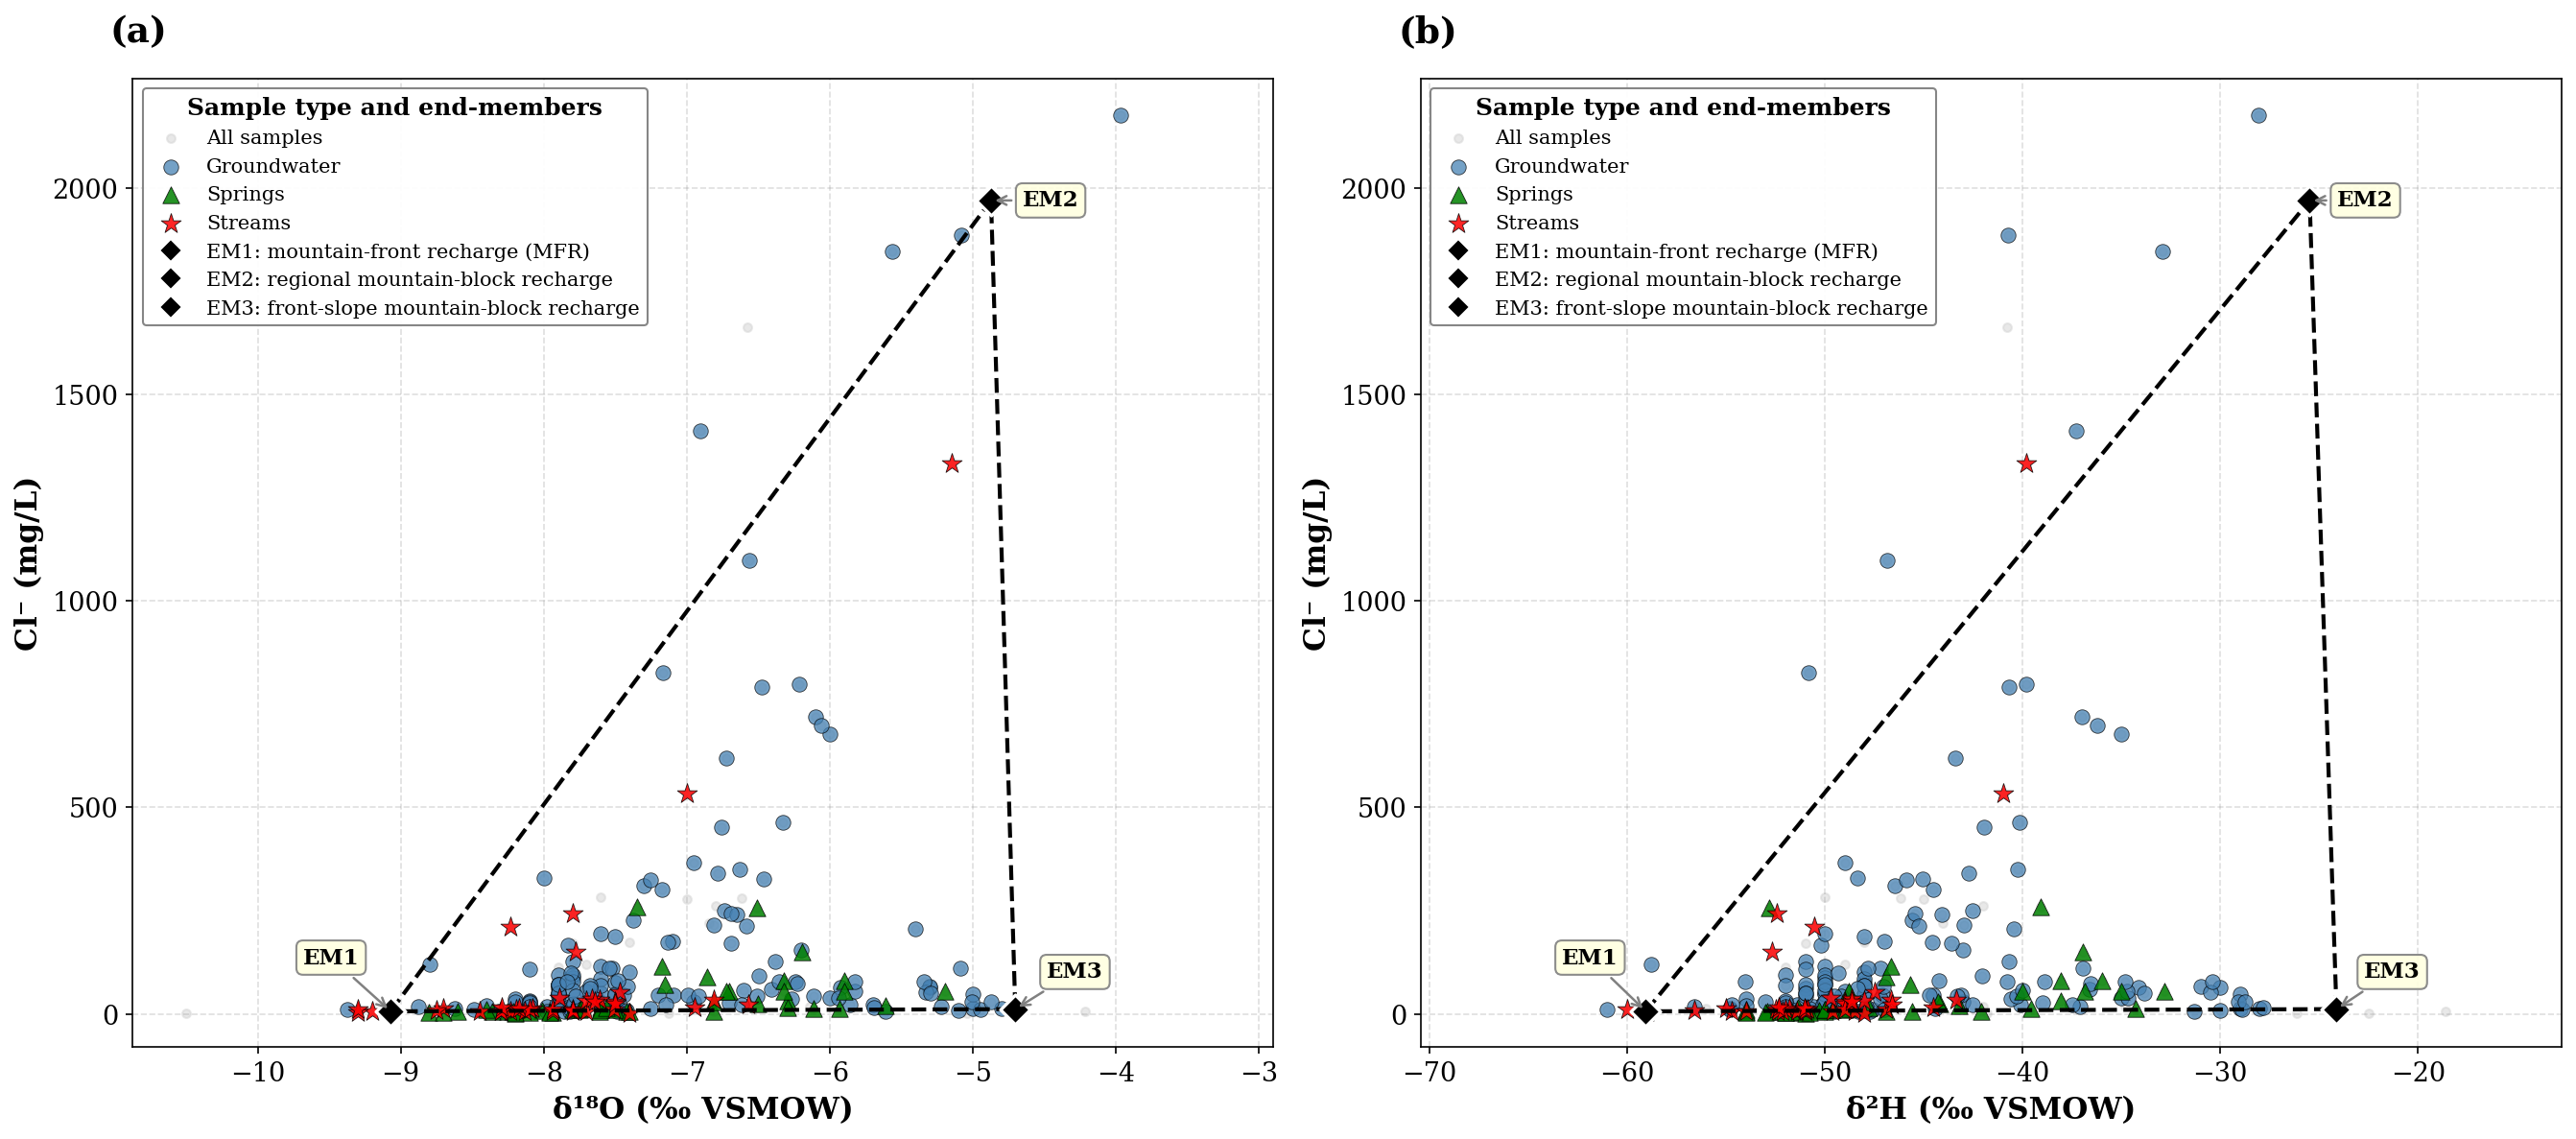

✓ Saved: Figure11_d18O_d2H_vs_Cl_mixing_panel.png


In [20]:
# ═══════════════════════════════════════════════════════════════════════
# Figure 11: mixing diagrams
#   (a) δ¹⁸O vs Cl⁻  - main mixing diagram
#   (b) δ²H  vs Cl⁻  - validation (LMWL-derived EM δ²H)
# Both panels use IDENTICAL marker style for sample types.
# Larger fonts, panel labels OUTSIDE axes.
# EM labels kept INSIDE the plot box (right-side EMs right-aligned).
# ═══════════════════════════════════════════════════════════════════════

from matplotlib.lines import Line2D

# ── Font sizes ─────────────────────────────────────────────────────────
LABEL_FS      = 15
TICK_FS       = 13
LEG_FS        = 11
LEG_TITLE_FS  = 12
EM_LBL_FS     = 11
PANEL_LBL_FS  = 18

# ── EM δ²H from LMWL (Raibi 2006): δ²H = 8·δ¹⁸O + 13.5 ─────────────────
for key in EM:
    EM[key]['d2H'] = 8.0 * EM[key]['d18O'] + 13.5
    print(f"{EM[key]['label']:25s}  δ¹⁸O = {EM[key]['d18O']:.2f}  |  "
          f"δ²H = {EM[key]['d2H']:.1f}  |  Cl⁻ = {EM[key]['Cl']:.1f}")

# ── unified style for both panels (same characters/colors) ─────────────
GW_STYLE     = dict(c='steelblue', marker='o', s=55, alpha=0.75,
                    edgecolors='k', linewidths=0.4)
SPRING_STYLE = dict(c='green',     marker='^', s=70, alpha=0.85,
                    edgecolors='k', linewidths=0.4)
STREAM_STYLE = dict(c='red',       marker='*', s=110, alpha=0.85,
                    edgecolors='k', linewidths=0.4)
ALLBG_STYLE  = dict(c='lightgray', s=18, alpha=0.5)
EM_STYLE     = dict(c='black', marker='D', s=110, edgecolors='white', linewidths=1.6)

# ── helper: draw a triangular mixing diagram on one axis ───────────────
def draw_mixing_panel(ax, x_col, em_xkey, x_label, panel_letter,
                      offset_map, x_pad_extra=1.0):
    """Plot one mixing diagram on the given axis.

    offset_map[key] = (ox, oy, ha): label offset from the EM point and
    horizontal alignment ('left' / 'right'); labels sit outside the triangle.
    """
    # ── background: all samples
    mask_bg = pool[x_col].notna() & pool['Cl (mg/L)'].notna()
    ax.scatter(pool.loc[mask_bg, x_col], pool.loc[mask_bg, 'Cl (mg/L)'],
               zorder=1, label='All samples', **ALLBG_STYLE)

    # ── groundwater (EMMA targets)
    mask_gw = df_emma[x_col].notna()
    ax.scatter(df_emma.loc[mask_gw, x_col], df_emma.loc[mask_gw, 'Cl (mg/L)'],
               zorder=3, label='Groundwater', **GW_STYLE)

    # ── springs
    sp = pool[(pool['Type'] == 'Spring') & pool[x_col].notna()]
    ax.scatter(sp[x_col], sp['Cl (mg/L)'],
               zorder=4, label='Springs', **SPRING_STYLE)

    # ── streams
    st = pool[(pool['Type'] == 'Stream') & pool[x_col].notna()]
    ax.scatter(st[x_col], st['Cl (mg/L)'],
               zorder=4, label='Streams', **STREAM_STYLE)

    # ── end-member points
    for key in ['EM1', 'EM2', 'EM3']:
        ax.scatter(EM[key][em_xkey], EM[key]['Cl'], zorder=6, **EM_STYLE)

    # ── mixing triangle
    tri = Polygon(
        [(EM['EM1'][em_xkey], EM['EM1']['Cl']),
         (EM['EM2'][em_xkey], EM['EM2']['Cl']),
         (EM['EM3'][em_xkey], EM['EM3']['Cl'])],
        fill=False, edgecolor='black', linestyle='--', linewidth=2, zorder=5
    )
    ax.add_patch(tri)

    # ── EM labels next to their vertex, outside the triangle (meanings in the legend)
    for key in ['EM1', 'EM2', 'EM3']:
        ox, oy, ha = offset_map[key]
        ax.annotate(
            key,
            xy=(EM[key][em_xkey], EM[key]['Cl']),
            xytext=(EM[key][em_xkey] + ox, EM[key]['Cl'] + oy),
            fontsize=EM_LBL_FS, fontweight='bold',
            ha=ha, va='center',
            bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow',
                      ec='gray', alpha=0.9),
            arrowprops=dict(arrowstyle='->', color='gray', lw=1.2),
            zorder=7,
        )

    # ── axes: auto-zoom with padding around EMs
    all_x  = [EM[k][em_xkey] for k in EM]
    all_Cl = [EM[k]['Cl']    for k in EM]
    pad_x  = 0.15 * (max(all_x) - min(all_x) + 1)
    ax.set_xlim(min(all_x) - pad_x - x_pad_extra, max(all_x) + pad_x + x_pad_extra)
    ax.set_ylim(-80, max(all_Cl) * 1.15)

    ax.set_xlabel(x_label,        fontsize=LABEL_FS, fontweight='bold')
    ax.set_ylabel('Cl⁻ (mg/L)',   fontsize=LABEL_FS, fontweight='bold')
    ax.tick_params(labelsize=TICK_FS)
    ax.grid(True, ls='--', alpha=0.25, color='gray')

    # one legend per panel: sample types + the meaning of EM1, EM2, EM3
    h, l = ax.get_legend_handles_labels()
    h += [Line2D([0], [0], marker='D', color='black', markersize=8, linestyle='None',
                 markeredgecolor='white', markeredgewidth=1.0, label=f"{k}: {n}")
          for k, n in [('EM1', 'mountain-front recharge (MFR)'),
                       ('EM2', 'regional mountain-block recharge'),
                       ('EM3', 'front-slope mountain-block recharge')]]
    l += [x.get_label() for x in h[-3:]]
    ax.legend(h, l, loc='upper left', fontsize=LEG_FS - 1, framealpha=0.95,
              edgecolor='gray', title='Sample type and end-members',
              title_fontproperties={'weight': 'bold', 'size': LEG_TITLE_FS})

    # panel label OUTSIDE axes
    ax.text(-0.02, 1.03, f'({panel_letter})', transform=ax.transAxes,
            fontsize=PANEL_LBL_FS, fontweight='bold',
            va='bottom', ha='left')


# ══════════ Build the merged figure ══════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax1, ax2 = axes

# Panel (a) - δ¹⁸O vs Cl⁻   offsets: (ox, oy, ha)
offset_d18O = {
    'EM1': (-0.22,  130, 'right'),   # bottom-left vertex  -> label to the left, outside the triangle
    'EM2': ( 0.22,    0, 'left'),    # top-right vertex    -> label to the right, same height
    'EM3': ( 0.22,   90, 'left'),    # bottom-right vertex -> label to the right, slightly above
}
draw_mixing_panel(ax1, x_col='δ18O (‰ VSMOW)', em_xkey='d18O',
                  x_label='δ¹⁸O (‰ VSMOW)', panel_letter='a',
                  offset_map=offset_d18O, x_pad_extra=1.0)

# Panel (b) - δ²H vs Cl⁻
offset_d2H = {
    'EM1': (-1.4,  130, 'right'),
    'EM2': ( 1.4,    0, 'left'),
    'EM3': ( 1.4,   90, 'left'),
}
draw_mixing_panel(ax2, x_col='δ2H (‰ VSMOW)', em_xkey='d2H',
                  x_label='δ²H (‰ VSMOW)', panel_letter='b',
                  offset_map=offset_d2H, x_pad_extra=6.0)

fig.tight_layout()
fig.savefig(DIR_FIGURES / 'Figure11_d18O_d2H_vs_Cl_mixing_panel.png',
            dpi=DPI, bbox_inches='tight')
plt.show()
print('✓ Saved: Figure11_d18O_d2H_vs_Cl_mixing_panel.png')

### <font color='orange'> **8) Mixing proportions** </font>

Three-end-member linear mixing system solved analytically.  
For each groundwater sample *s* with tracers (δ¹⁸O_s, Cl_s), the fractions  
R_a (EM1), R_b (EM2), R_c (EM3) are obtained from the mass-balance equations:

$$R_a + R_b + R_c = 1$$
$$\delta_s = R_a \cdot \delta_a + R_b \cdot \delta_b + R_c \cdot \delta_c$$
$$C_s = R_a \cdot C_a + R_b \cdot C_b + R_c \cdot C_c$$

In [21]:
def emma_3em(d18O_s, Cl_s, em):
    """
    Solve 3-end-member mixing for one sample.
    Returns (Ra, Rb, Rc) = fractions of EM1, EM2, EM3.
    """
    da, Ca = em['EM1']['d18O'], em['EM1']['Cl']
    db, Cb = em['EM2']['d18O'], em['EM2']['Cl']
    dc, Cc = em['EM3']['d18O'], em['EM3']['Cl']
    ds, Cs = d18O_s, Cl_s

    denom_a = (da - dc) * (Cb - Cc) - (Ca - Cc) * (db - dc)
    denom_b = (db - dc) * (Ca - Cc) - (Cb - Cc) * (da - dc)

    if abs(denom_a) < 1e-12 or abs(denom_b) < 1e-12:
        return np.nan, np.nan, np.nan

    Ra = ((ds - dc) * (Cb - Cc) - (Cs - Cc) * (db - dc)) / denom_a
    Rb = ((ds - dc) * (Ca - Cc) - (Cs - Cc) * (da - dc)) / denom_b
    Rc = 1.0 - Ra - Rb

    return Ra, Rb, Rc


# ── apply to all EMMA-ready groundwater ───────────────────────────────────
results = df_emma.apply(
    lambda row: emma_3em(
        row['δ18O (‰ VSMOW)'], row['Cl (mg/L)'], EM
    ),
    axis=1, result_type='expand',
)
results.columns = ['Ra_MFR', 'Rb_RegMBR', 'Rc_FSMB']
df_emma = pd.concat([df_emma, results], axis=1)

# ── QC: valid if all fractions in [0, 1] ──────────────────────────────────
df_emma['VALID'] = (
    (df_emma['Ra_MFR'] >= 0) & (df_emma['Ra_MFR'] <= 1) &
    (df_emma['Rb_RegMBR'] >= 0) & (df_emma['Rb_RegMBR'] <= 1) &
    (df_emma['Rc_FSMB'] >= 0) & (df_emma['Rc_FSMB'] <= 1)
)

n_valid = df_emma['VALID'].sum()
n_invalid = (~df_emma['VALID']).sum()
print(f'EMMA results: {n_valid} valid, {n_invalid} invalid '
      f'({100 * n_valid / len(df_emma):.1f}% valid)')

# ── quick stats on valid samples ──────────────────────────────────────────
df_valid = df_emma[df_emma['VALID']].copy()
for col, label in [('Ra_MFR', 'MFR'), ('Rb_RegMBR', 'Regional MBR'),
                    ('Rc_FSMB', 'Front-slope MBR')]:
    print(f'  {label:18s}: mean={df_valid[col].mean():.3f}, '
          f'median={df_valid[col].median():.3f}, '
          f'std={df_valid[col].std():.3f}')

EMMA results: 132 valid, 16 invalid (89.2% valid)
  MFR               : mean=0.535, median=0.598, std=0.219
  Regional MBR      : mean=0.064, median=0.028, std=0.098
  Front-slope MBR   : mean=0.401, median=0.330, std=0.222


### <font color='orange'> **9) Error propagation (Monte Carlo, N = 1,000)** </font>

Following Liu and Yamanaka (2012) and Phillips and Gregg (2001), uncertainty in  
EM compositions is propagated via Monte Carlo simulation. Each EM is perturbed  
N=1000 times within its standard deviation, and EMMA is recalculated.

In [22]:
# ── Monte Carlo settings ─────────────────────────────────────────────────────
N_MC = 1000
np.random.seed(42)

n_samples = len(df_emma)
mc_Ra = np.zeros((n_samples, N_MC))
mc_Rb = np.zeros((n_samples, N_MC))
mc_Rc = np.zeros((n_samples, N_MC))

d18O_vals = df_emma['δ18O (‰ VSMOW)'].values
Cl_vals = df_emma['Cl (mg/L)'].values

print(f'Running {N_MC} Monte Carlo iterations for {n_samples} samples...')

for i in range(N_MC):
    # perturb each EM within its SD
    em_pert = {}
    for key in ['EM1', 'EM2', 'EM3']:
        em_pert[key] = {
            'd18O': EM[key]['d18O'] + np.random.normal(0, EM[key]['d18O_sd']),
            'Cl': max(0, EM[key]['Cl'] + np.random.normal(0, EM[key]['Cl_sd'])),
        }

    for j in range(n_samples):
        ra, rb, rc = emma_3em(d18O_vals[j], Cl_vals[j], em_pert)
        mc_Ra[j, i] = ra
        mc_Rb[j, i] = rb
        mc_Rc[j, i] = rc

# ── standard error = std of MC results ────────────────────────────────────
df_emma['SE_Ra'] = np.nanstd(mc_Ra, axis=1)
df_emma['SE_Rb'] = np.nanstd(mc_Rb, axis=1)
df_emma['SE_Rc'] = np.nanstd(mc_Rc, axis=1)

print('Monte Carlo complete.')
print(f'\nMean SE: Ra={df_emma["SE_Ra"].mean():.4f}, '
      f'Rb={df_emma["SE_Rb"].mean():.4f}, '
      f'Rc={df_emma["SE_Rc"].mean():.4f}')

Running 1000 Monte Carlo iterations for 148 samples...
Monte Carlo complete.

Mean SE: Ra=0.0551, Rb=0.0093, Rc=0.0569


### <font color='orange'> **10) Figure SM12: box plots of the mixing proportions** </font>

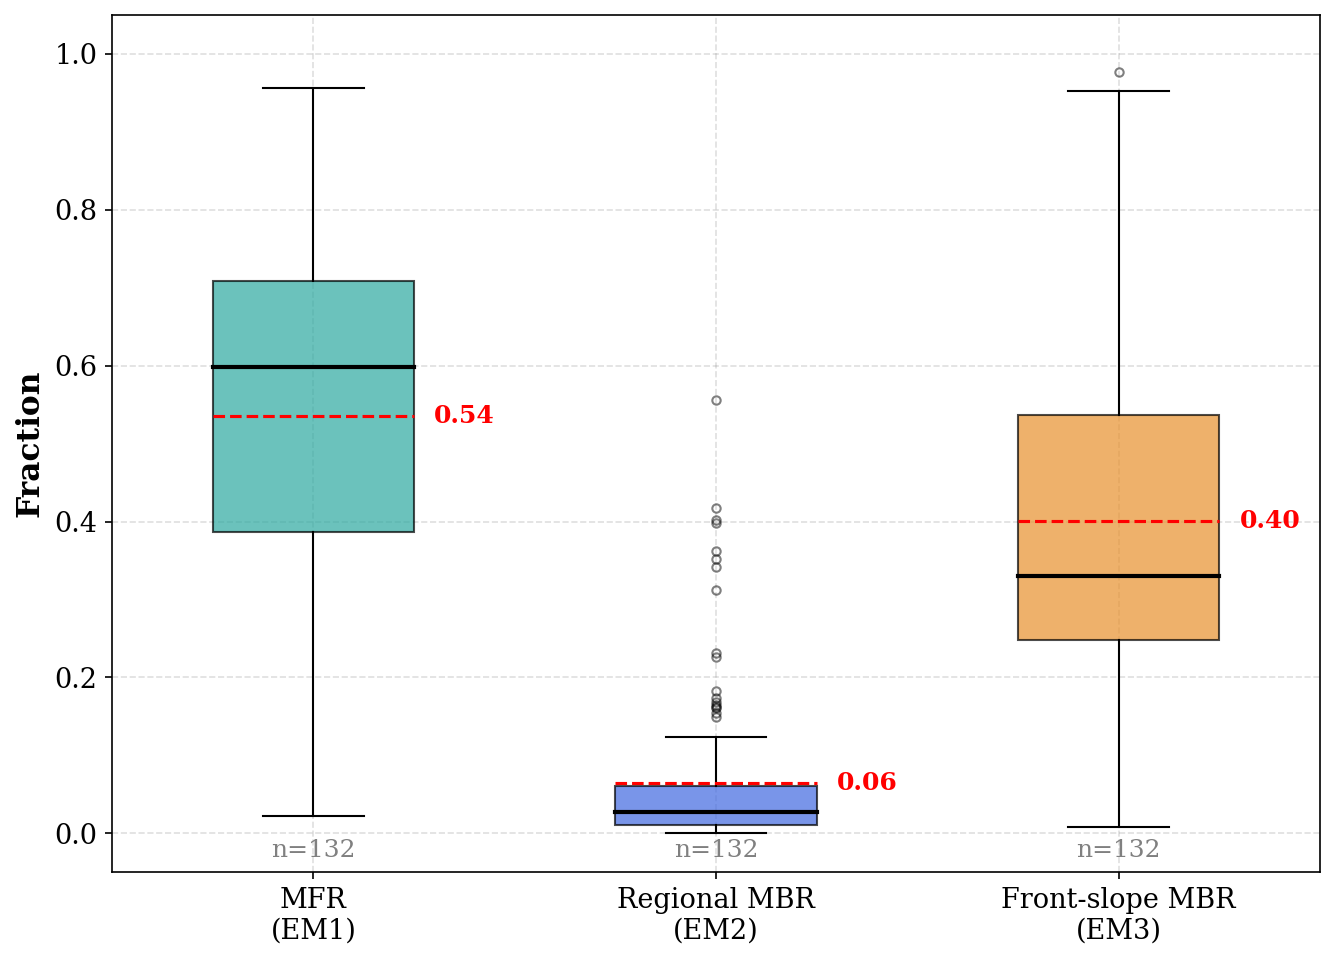

Saved: SM12_EMMA_boxplots


In [23]:
# ── boxplot of valid EMMA fractions ───────────────────────────────────────
df_valid = df_emma[df_emma['VALID']].copy()

# ── Font sizes ───────────────────────────────────────────────────────────
LABEL_FS = 15
TICK_FS  = 13
ANNO_FS  = 12

fig, ax = plt.subplots(figsize=(9, 6.5))

box_data = [
    df_valid['Ra_MFR'].values,
    df_valid['Rb_RegMBR'].values,
    df_valid['Rc_FSMB'].values,
]
box_labels = ['MFR\n(EM1)', 'Regional MBR\n(EM2)', 'Front-slope MBR\n(EM3)']
box_colors = ['#2ca9a0', '#4169e1', '#e8912d']

bp = ax.boxplot(box_data, labels=box_labels, patch_artist=True,
                widths=0.5, showmeans=False,
                medianprops=dict(color='black', lw=2),
                flierprops=dict(marker='o', markersize=4, alpha=0.5))

for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# mean dashed lines
for i, d in enumerate(box_data):
    mean_val = np.mean(d)
    ax.hlines(mean_val, i + 0.75, i + 1.25, colors='red',
              linestyles='dashed', linewidths=1.5, zorder=4)
    ax.text(i + 1.30, mean_val, f'{mean_val:.2f}', va='center',
            fontsize=ANNO_FS, color='red', fontweight='bold')

# n= annotation
for i in range(3):
    ax.text(i + 1, -0.03, f'n={len(box_data[i])}',
            ha='center', fontsize=ANNO_FS, color='gray')

ax.set_ylabel('Fraction', fontsize=LABEL_FS, fontweight='bold')
ax.tick_params(labelsize=TICK_FS)
ax.set_ylim(-0.05, 1.05)

fig.tight_layout()
fig.savefig(DIR_FIGURES / 'SM12_EMMA_boxplots.png',
            dpi=DPI, bbox_inches='tight')
plt.show()
print('Saved: SM12_EMMA_boxplots')

### <font color='orange'> **11) Figure SM11: mean contribution of each source** </font>

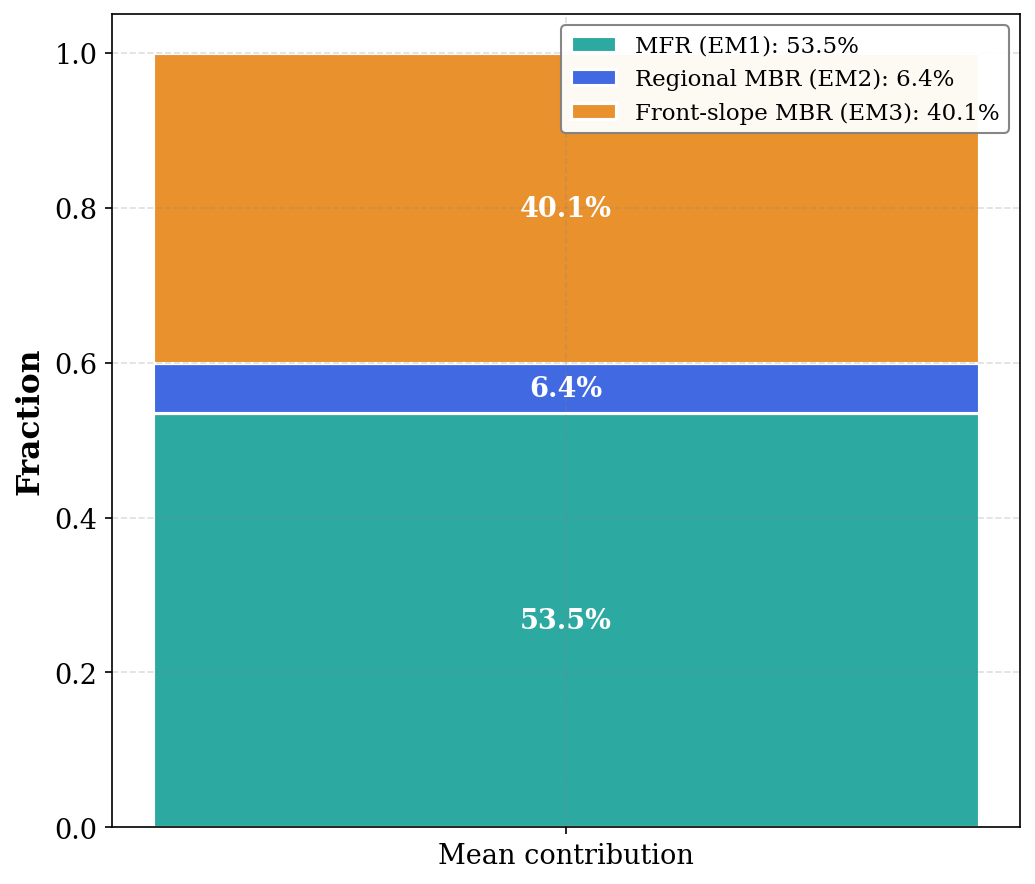

Saved: SM11_EMMA_stacked_bar


In [24]:
# ── stacked bar ─────────────────────────────────────────────────────────────
df_valid = df_emma[df_emma['VALID']].copy()

# ── Font sizes ───────────────────────────────────────────────────────────
LABEL_FS = 15
TICK_FS  = 13
LEG_FS   = 11
BAR_FS   = 13

means = [
    df_valid['Ra_MFR'].mean(),
    df_valid['Rb_RegMBR'].mean(),
    df_valid['Rc_FSMB'].mean(),
]
labels_bar = ['MFR (EM1)', 'Regional MBR (EM2)', 'Front-slope MBR (EM3)']
colors_bar = ['#2ca9a0', '#4169e1', '#e8912d']

fig, ax = plt.subplots(figsize=(7, 6))
bottom = 0
for m, lab, col in zip(means, labels_bar, colors_bar):
    ax.bar('Mean contribution', m, bottom=bottom, color=col,
           edgecolor='white', linewidth=1.5, label=f'{lab}: {m:.1%}')
    ax.text(0, bottom + m / 2, f'{m:.1%}', ha='center', va='center',
            fontsize=BAR_FS, fontweight='bold', color='white')
    bottom += m

ax.set_ylabel('Fraction', fontsize=LABEL_FS, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend(loc='upper right', framealpha=0.95, edgecolor='gray', fontsize=LEG_FS)
ax.tick_params(labelsize=TICK_FS)

fig.tight_layout()
fig.savefig(DIR_FIGURES / 'SM11_EMMA_stacked_bar.png',
            dpi=DPI, bbox_inches='tight')
plt.show()
print('Saved: SM11_EMMA_stacked_bar')

### <font color='orange'> **12) Tritium cross-check (Figure SM13, only if ³H is available)** </font>

> Tritium gives an independent check of the mixing results: MFR-dominated samples are expected to have higher ³H (recent mountain recharge) than MBR-dominated samples (older, deeper flow paths). The shared data file does not include the ³H column, so this section only assigns the dominant source and skips the figure.

In [25]:
# ── Create Dominant column if not present ─────────────────────────────────
label_map = {'Ra_MFR': 'MFR', 'Rb_RegMBR': 'Regional MBR', 'Rc_FSMB': 'Front-slope MBR'}
if 'Dominant' not in df_emma.columns:
    frac_cols = ['Ra_MFR', 'Rb_RegMBR', 'Rc_FSMB']
    existing_frac = [c for c in frac_cols if c in df_emma.columns]
    df_emma['Dominant'] = df_emma[existing_frac].idxmax(axis=1).map(label_map)

# ── subset: valid EMMA with 3H data (empty when the 3H column is absent) ──
if HAS_3H:
    df_3h = df_emma[(df_emma['VALID']) & (df_emma['3H_value'].notna())].copy()
    print(f'Valid EMMA samples with 3H: {len(df_3h)}')
else:
    df_3h = df_emma.iloc[0:0]
    print('3H not available in the shared data: Figure SM13 is not produced (tritium data available on request).')

# ── Font sizes ───────────────────────────────────────────────────────────
LABEL_FS = 15
TICK_FS  = 13

if len(df_3h) > 0:
    # ── median 3H by dominant source ─────────────────────────────────────────
    print('\nMedian 3H by dominant source:')
    for dom in ['MFR', 'Regional MBR', 'Front-slope MBR']:
        sub = df_3h[df_3h['Dominant'] == dom]
        if len(sub) > 0:
            print(f'  {dom:12s}: median={sub["3H_value"].median():.2f} TU, '
                  f'n={len(sub)}')
        else:
            print(f'  {dom:12s}: no samples')

    # ── boxplot ───────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(9, 6.5))

    order = ['MFR', 'Regional MBR', 'Front-slope MBR']
    palette = {'MFR': '#2ca9a0', 'Regional MBR': '#4169e1', 'Front-slope MBR': '#e8912d'}

    # filter to groups that actually exist in the data
    existing = [g for g in order if g in df_3h['Dominant'].values]

    sns.boxplot(data=df_3h, x='Dominant', y='3H_value',
                order=existing, palette=palette,
                width=0.5, ax=ax)
    sns.stripplot(data=df_3h, x='Dominant', y='3H_value',
                  order=existing, color='black', size=5,
                  alpha=0.5, jitter=True, ax=ax)

    ax.set_xlabel('Dominant recharge source', fontsize=LABEL_FS, fontweight='bold')
    ax.set_ylabel('³H (TU)', fontsize=LABEL_FS, fontweight='bold')
    ax.tick_params(labelsize=TICK_FS)

    fig.tight_layout()
    fig.savefig(DIR_FIGURES / 'SM13_3H_by_dominant_source.png',
                dpi=DPI, bbox_inches='tight')
    plt.show()
    print('Saved: SM13_3H_by_dominant_source')

3H not available in the shared data: Figure SM13 is not produced (tritium data available on request).


### <font color='orange'> **13) Export the results** </font>

#### Output file: `outputs/tables/EMMA_results.xlsx`

**Sheet 1: Valid_EMMA**: Groundwater samples with valid EMMA proportions (all R between 0 and 1)

**Sheet 2: Invalid_EMMA**: Groundwater samples outside the mixing triangle (at least one R < 0 or R > 1)

**Sheet 3: EndMembers**: End-member definitions with SD

**Sheet 4: Summary**: Counts and mean contributions

#### Column descriptions (Valid_EMMA & Invalid_EMMA sheets)

| Column | Description | Unit / Values |
|--------|-------------|---------------|
| **Reference** | Literature source of the sample | e.g. "(EL FARCHOUNI et al., 2025)" |
| **SampleID** | Unique sample identifier | e.g. "S18", "S421" |
| **X** | Easting coordinate (Lambert / projected) | meters |
| **Y** | Northing coordinate (Lambert / projected) | meters |
| **Z** | Sampling altitude (elevation) | m a.s.l. |
| **Sampling date** | Date of sample collection | yyyy-mm-dd |
| **Type** | Water type | "Groundwater" (all in EMMA sheets) |
| **δ¹⁸O (‰ VSMOW)** | Oxygen-18 isotope ratio | ‰ vs VSMOW |
| **δ²H (‰ VSMOW)** | Deuterium isotope ratio | ‰ vs VSMOW |
| **d-excess (‰)** | Deuterium excess = δ²H − 8×δ¹⁸O | ‰ |
| **Na (mg/L)** | Sodium concentration | mg/L |
| **Cl (mg/L)** | Chloride concentration | mg/L |
| **EC (μS/cm)** | Electrical conductivity | μS/cm |
| **Cluster** | SOM cluster of the sample | 1 to 4 (NaN if the sample has no complete major-ion analysis) |
| **NaCl_ratio** | Na⁺/Cl⁻ molar ratio | dimensionless |
| **reactive_Cl** | Cl⁻ conservativeness flag | False = conservative, True = reactive (excluded) |
| **Ra_MFR** | EMMA contribution of EM1, mountain-front recharge | 0–1 (fraction) |
| **Rb_RegMBR** | EMMA contribution of EM2, regional mountain-block recharge | 0–1 (fraction) |
| **Rc_FSMB** | EMMA contribution of EM3, front-slope mountain-block recharge | 0–1 (fraction) |
| **VALID** | EMMA validity flag | True = all R in [0,1]; False = outside triangle |
| **SE_Ra** | Monte Carlo standard error of Ra (N=1000) | fraction |
| **SE_Rb** | Monte Carlo standard error of Rb (N=1000) | fraction |
| **SE_Rc** | Monte Carlo standard error of Rc (N=1000) | fraction |
| **Dominant** | Dominant recharge source (highest R) | "MFR", "Regional MBR", or "Front-slope MBR" |

#### EndMembers sheet columns

| Column | Description |
|--------|-------------|
| **End-member** | Name: EM1 (MFR), EM2 (Regional MBR), EM3 (Front-slope MBR) |
| **d18O_mean** | Mean δ¹⁸O of the samples used to define this EM (‰) |
| **d18O_SD** | Standard deviation of δ¹⁸O in EM-defining samples |
| **Cl_mean_mg_L** | Mean Cl⁻ of the samples used to define this EM (mg/L) |
| **Cl_SD_mg_L** | Standard deviation of Cl⁻ in EM-defining samples |

In [26]:
# ── prepare export dataframes ───────────────────────────────────────────────
df_valid_out = df_emma[df_emma['VALID']].copy()
df_invalid_out = df_emma[~df_emma['VALID']].copy()

# end-member definitions
em_export = pd.DataFrame({
    'End-member': ['EM1 (MFR)', 'EM2 (Regional MBR)', 'EM3 (Front-slope MBR)'],
    'd18O_mean': [EM['EM1']['d18O'], EM['EM2']['d18O'], EM['EM3']['d18O']],
    'd18O_SD': [EM['EM1']['d18O_sd'], EM['EM2']['d18O_sd'], EM['EM3']['d18O_sd']],
    'Cl_mean_mg_L': [EM['EM1']['Cl'], EM['EM2']['Cl'], EM['EM3']['Cl']],
    'Cl_SD_mg_L': [EM['EM1']['Cl_sd'], EM['EM2']['Cl_sd'], EM['EM3']['Cl_sd']],
})

# summary statistics
summary = pd.DataFrame({
    'Metric': [
        'Total GW samples (EMMA-ready)',
        'Valid EMMA',
        'Invalid EMMA',
        'Valid %',
        'Mean Ra (MFR)',
        'Mean Rb (Regional MBR)',
        'Mean Rc (Front-slope MBR)',
        'Mean SE Ra',
        'Mean SE Rb',
        'Mean SE Rc',
    ],
    'Value': [
        len(df_emma),
        len(df_valid_out),
        len(df_invalid_out),
        f'{100 * len(df_valid_out) / len(df_emma):.1f}%',
        f'{df_valid_out["Ra_MFR"].mean():.4f}',
        f'{df_valid_out["Rb_RegMBR"].mean():.4f}',
        f'{df_valid_out["Rc_FSMB"].mean():.4f}',
        f'{df_valid_out["SE_Ra"].mean():.4f}',
        f'{df_valid_out["SE_Rb"].mean():.4f}',
        f'{df_valid_out["SE_Rc"].mean():.4f}',
    ],
})

# ── write multi-sheet Excel ───────────────────────────────────────────────
out_path = DIR_TABLES / 'EMMA_results.xlsx'
with pd.ExcelWriter(out_path, engine='openpyxl') as writer:
    df_valid_out.to_excel(writer, sheet_name='Valid_EMMA', index=False)
    df_invalid_out.to_excel(writer, sheet_name='Invalid_EMMA', index=False)
    em_export.to_excel(writer, sheet_name='EndMembers', index=False)
    summary.to_excel(writer, sheet_name='Summary', index=False)

print(f'Results exported to: {out_path.relative_to(ROOT)}')
print(f'\n{"="*60}')
print('FINAL SUMMARY')
print(f'{"="*60}')
print(summary.to_string(index=False))
print(f'{"="*60}')

# ── Check against the article ────────────────────────────────────────
assert (len(df_emma), len(df_valid_out)) == (148, 132)
assert tuple(round(100 * df_valid_out[c].mean(), 1) for c in ['Ra_MFR', 'Rb_RegMBR', 'Rc_FSMB']) == (53.5, 6.4, 40.1)
assert np.allclose([100 * df_valid_out[c].mean() for c in ['SE_Ra', 'SE_Rb', 'SE_Rc']], [5.2, 0.7, 5.3], atol=0.1)
print("✓ Matches the article: 148 samples, 132 valid (89.2 %); MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %; Monte Carlo SE 5.2 / 0.7 / 5.3 %.")

Results exported to: outputs\tables\EMMA_results.xlsx

FINAL SUMMARY
                       Metric  Value
Total GW samples (EMMA-ready)    148
                   Valid EMMA    132
                 Invalid EMMA     16
                      Valid %  89.2%
                Mean Ra (MFR) 0.5350
       Mean Rb (Regional MBR) 0.0640
    Mean Rc (Front-slope MBR) 0.4010
                   Mean SE Ra 0.0515
                   Mean SE Rb 0.0074
                   Mean SE Rc 0.0528
✓ Matches the article: 148 samples, 132 valid (89.2 %); MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %; Monte Carlo SE 5.2 / 0.7 / 5.3 %.


---
**Figures:** Figure 11, SM10, SM11, SM12 in `outputs/figures/` (SM13 needs the tritium data)

**Table:** `outputs/tables/EMMA_results.xlsx`

**Next:** `02_EMMA_sensitivity.ipynb` (scenarios S1-S5; Table SM2, Figure SM14)